# 18 — El panel de todas las EPS

## Qué pidió el propietario

«No tenemos una variable que mida el estado de **todas** las EPS; es como si supusiera que la Nueva EPS es la
única que existe.» Este cuaderno arma ese panel con dos miradas:
- **desde dentro**, con el triage del propio hospital por asegurador (2020-2026);
- **desde fuera**, con la afiliación mensual de MinSalud por EPS en Manizales y las medidas de la
  Supersalud, que desde el 2026-10-05 se capturan solas cada semana (`calendarios/docs/CAPTURAS.md`).

Método en la fila `panel_eps` de `variables.csv`, fijado antes de mirar. Este cuaderno es **descriptivo**: mira
2025-2026 porque ahí ocurren los escalones de la red. **No elige ni prueba ningún modelo**; eso queda para el
cuaderno 22.

In [1]:
import sys, pathlib, warnings, re, glob
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ / "notebooks")); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from matplotlib import pyplot as plt
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
ESCALONES = ["2024-04-01", "2025-11-15", "2026-03-01", "2026-07-01"]

def grupo(e):
    e = str(e).upper()
    reglas = [("Nueva EPS", r"NUEVA (EMPRESA PROMOTORA|EPS)(?!.*COMPLEMENT)"), ("SURA", r"^EPS SURA|EPS SURAMERICANA"),
              ("Salud Total", r"SALUD TOTAL"), ("Sanitas", r"^EPS SANITAS|SANITAS EPS"), ("Asmet", r"ASMET"),
              ("Magisterio (FOMAG)", r"FIDEICOMISOS|FIDUPREVISORA|MAGISTERIO"), ("Medimás", r"MEDIMAS"),
              ("SOAT y accidentes", r"SEGUROS|MUNDIAL|PREVISORA S\.A\. COMPA|SOAT|ARL|POSITIVA|LIBERTY|ALLIANZ|AXA"),
              ("Territorial (no asegurados)", r"TERRITORIAL|SECRETARIA|MUNICIPIO|DEPARTAMENTO"), ("Particulares", r"PARTICULAR"),
              ("Prepagadas", r"PREPAGADA|COLSANITAS|COLMEDICA|MEDISANITAS")]
    return next((g for g, p in reglas if re.search(p, e)), "Otras")
te = pd.read_parquet(RAIZ / "salidas/triage_entidad.parquet", columns=["dia", "entidad", "n"]); te["dia"] = pd.to_datetime(te.dia)
te["grupo"] = te.entidad.map({e: grupo(e) for e in te.entidad.dropna().unique()}).fillna("Otras")
D = te.pivot_table(index="dia", columns="grupo", values="n", aggfunc="sum").reindex(pd.date_range("2020-01-01", "2026-09-20")).fillna(0)
D.loc["2024-03-19":"2024-03-21"] = np.nan
print("Grupos y triages totales 2020-2026:"); D.sum().sort_values(ascending=False).astype(int)

Grupos y triages totales 2020-2026:


grupo
Nueva EPS                      252586
SURA                            95995
Otras                           24112
SOAT y accidentes               19192
Salud Total                      7837
Prepagadas                       7588
Particulares                     5576
Magisterio (FOMAG)               5542
Territorial (no asegurados)      5175
Asmet                            3600
Medimás                          3179
Sanitas                          2876
dtype: int32

---
# 1. Quién llega al hospital, mes a mes

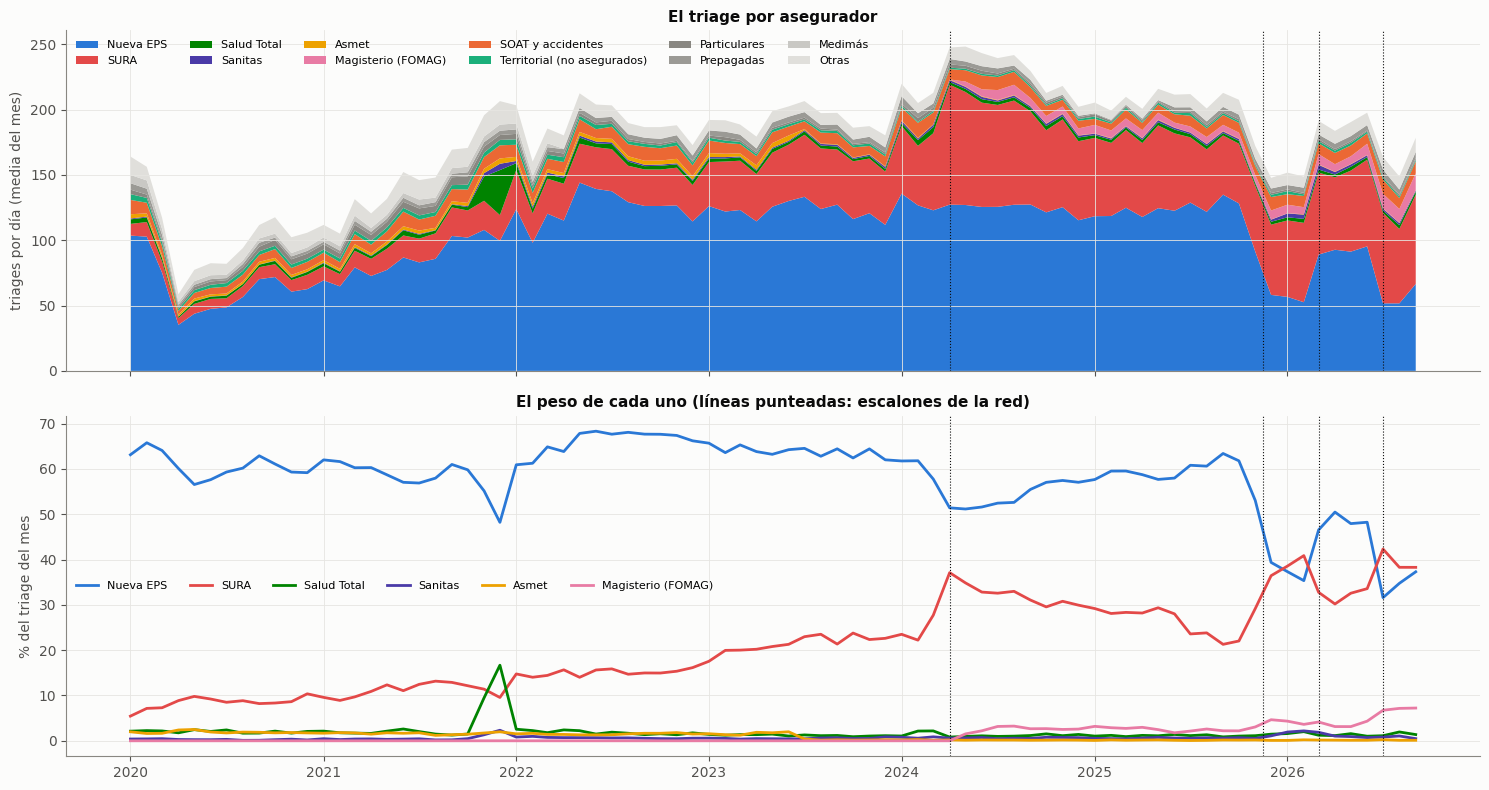

grupo,Nueva EPS,SURA,Salud Total,Sanitas,Asmet,Magisterio (FOMAG),SOAT y accidentes,Territorial (no asegurados),Particulares,Prepagadas,Medimás,Otras,total
2020,64.8,8.6,2.2,0.3,2.0,0.0,5.9,2.8,3.0,2.6,3.5,10.1,105.8
2021,86.1,16.8,6.5,1.0,2.4,0.0,8.4,3.1,4.7,2.7,3.8,13.7,149.2
2022,125.3,28.5,3.5,1.3,2.8,0.0,8.9,2.8,2.2,3.4,1.1,9.7,189.5
2023,122.9,41.1,2.3,1.0,1.8,0.0,7.6,1.7,1.4,3.8,0.1,8.5,192.2
2024,125.6,69.6,2.9,1.5,0.4,4.0,8.7,1.2,1.8,3.1,0.1,8.1,227.0
2025,115.8,53.9,2.3,1.2,0.3,5.4,6.8,1.4,1.3,2.3,0.1,8.9,199.7
2026,72.2,62.0,2.4,2.1,0.3,8.2,8.7,1.6,1.2,4.1,0.0,9.8,172.6


In [2]:
M = D.resample("MS").mean()
orden = ["Nueva EPS", "SURA", "Salud Total", "Sanitas", "Asmet", "Magisterio (FOMAG)", "SOAT y accidentes", "Territorial (no asegurados)", "Particulares", "Prepagadas", "Medimás", "Otras"]
cols = [AZUL, ROJO, VERDE, VIOLETA, AMARILLO, MAGENTA, NARANJA, AQUA, MUDO, "#9b9a95", "#c9c8c4", "#e0dfdb"]
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
axes[0].stackplot(M.index, [M[g] for g in orden], labels=orden, colors=cols, lw=0)
axes[0].set_ylabel("triages por día (media del mes)"); axes[0].legend(ncol=6, fontsize=8, loc="upper left"); axes[0].set_title("El triage por asegurador")
W = M.div(M.sum(axis=1), axis=0) * 100
for g, c in zip(orden[:6], cols[:6]): axes[1].plot(W.index, W[g], color=c, lw=2, label=g)
for f in ESCALONES: [ax.axvline(pd.Timestamp(f), color=TINTA, lw=.8, ls=":") for ax in axes]
axes[1].set_ylabel("% del triage del mes"); axes[1].legend(ncol=6, fontsize=8); axes[1].set_title("El peso de cada uno (líneas punteadas: escalones de la red)")
plt.tight_layout(); plt.show()
anual = D.groupby(D.index.year).mean()[orden].round(1); anual["total"] = anual.sum(axis=1); anual

**Lectura.**

- **El hospital depende de dos aseguradoras.** Nueva EPS y SURA son el 80-90 % del triage. Las demás EPS (Salud Total, Sanitas, Asmet) son pequeñas aquí: 1-3 triages por día cada una.
- **SURA creció sin parar:** 8,6 triages por día en 2020, **69,6 en 2024** y 62,0 en 2026.
- **Nueva EPS se mantuvo cerca de 125 por día de 2022 a 2024 y se desplomó en 2026, a 72.**
- **Aparecen jugadores nuevos:** el magisterio (FOMAG) desde 2024, con 8 por día en 2026.
- **Un modelo que solo mira a Nueva EPS ve la mitad de la red.** El crecimiento de SURA explica la subida de 2022-2024 tanto como Nueva EPS explica la caída de 2026.

---
# 2. Sustitución: cuando Nueva EPS cae, ¿quién compensa?

Para cada escalón: el triage diario medio de Nueva EPS y del resto en los 60 días antes y los 60 días después,
dejando fuera la semana del escalón.

In [3]:
filas = []
for f in ESCALONES:
    f = pd.Timestamp(f); a = D.loc[f - pd.Timedelta(days=67):f - pd.Timedelta(days=8)]; d = D.loc[f + pd.Timedelta(days=7):f + pd.Timedelta(days=66)]
    ne_a, ne_d = a["Nueva EPS"].mean(), d["Nueva EPS"].mean(); re_a, re_d = a.drop(columns="Nueva EPS").sum(axis=1).mean(), d.drop(columns="Nueva EPS").sum(axis=1).mean()
    su_a, su_d = a["SURA"].mean(), d["SURA"].mean()
    filas.append({"escalón": f.date(), "Nueva EPS antes": ne_a, "Nueva EPS después": ne_d, "cambio Nueva EPS": ne_d - ne_a,
                  "resto antes": re_a, "resto después": re_d, "cambio resto": re_d - re_a, "de eso, SURA": su_d - su_a,
                  "compensa el resto %": 100 * (re_d - re_a) / -(ne_d - ne_a) if ne_d != ne_a else np.nan,
                  "cambio del total %": 100 * ((ne_d + re_d) / (ne_a + re_a) - 1)})
pd.DataFrame(filas).set_index("escalón").round(1)

,Nueva EPS antes,Nueva EPS después,cambio Nueva EPS,resto antes,resto después,cambio resto,"de eso, SURA",compensa el resto %,cambio del total %
escalón,,,,,,,,,
2024-04-01,128.9,128.7,-0.2,78.4,123.1,44.7,39.7,19538.7,21.5
2025-11-15,128.8,58.4,-70.4,79.0,90.5,11.5,8.9,16.4,-28.3
2026-03-01,53.8,91.6,37.8,95.0,95.7,0.7,-0.5,-1.9,25.9
2026-07-01,94.0,53.0,-41.0,100.1,104.5,4.4,-0.3,10.7,-18.9


**Lectura.**

- **Cuando Nueva EPS cae, el resto casi no compensa.**
  - **Noviembre de 2025:** Nueva EPS pierde 70 triages al día y el resto sube 11,5, solo el 16 % del hueco. El total cae un 28 %.
  - **Julio de 2026:** compensa el 11 %, y el total cae un 19 %.
- **Los pacientes de Nueva EPS que dejan de llegar no aparecen en el SES por otra vía.** Se atienden en otro lugar o no se atienden.
- **Marzo de 2026 es la imagen inversa:** Nueva EPS recupera 38 triages al día, el resto no se mueve y el total sube un 26 %. Parece una reanudación de servicios.
- **El escalón de abril de 2024 no fue de Nueva EPS** (se movió −0,2) **sino de SURA**, que ganó 40 triages al día de golpe: probablemente un convenio nuevo con el hospital. **Los escalones de la red no son de una sola EPS.**

---
# 3. Afiliados contra uso: ¿se van los afiliados o no logran entrar?

Afiliación mensual por EPS en **Manizales** (MinSalud, julio de 2025 a agosto de 2026, capturada el
2026-10-05) frente al triage del hospital de cada EPS.

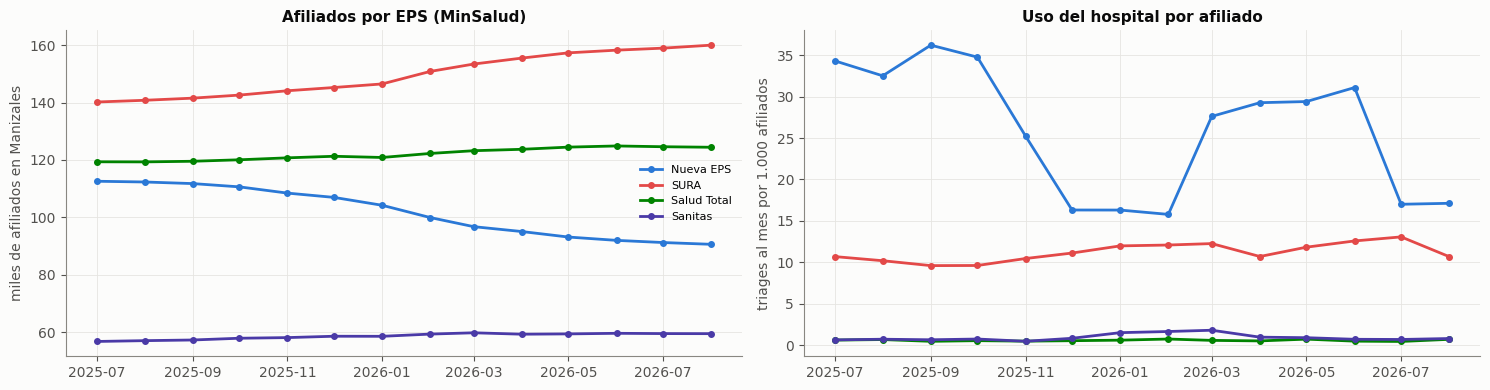

,afiliados jul-2025,afiliados ago-2026,cambio afiliados %,triage/día jul-2025,triage/día ago-2026,cambio triage %,"uso por afiliado, cambio %"
Nueva EPS,112573.0,90585.0,-19.5,128.8,51.7,-59.9,-50.1
SURA,140195.0,160024.0,14.1,50.0,57.0,14.0,-0.1
Salud Total,119354.0,124423.0,4.2,2.4,2.9,20.0,15.1
Sanitas,56713.0,59430.0,4.8,1.2,1.6,32.4,26.4


In [4]:
MESES = {"ene": 1, "feb": 2, "mar": 3, "abr": 4, "may": 5, "jun": 6, "jul": 7, "ago": 8, "sep": 9, "oct": 10, "nov": 11, "dic": 12}
filas = []
for f in glob.glob(str(RAIZ / "calendarios/capturas/afiliacion/*_caldas.csv.gz")):
    m = re.search(r"(ene|feb|mar|abr|may|jun|jul|ago|sep|oct|nov|dic)[a-z]*[-_]?(\d{4})", f.lower()); fecha = pd.Timestamp(int(m.group(2)), MESES[m.group(1)], 1)
    d = pd.read_csv(f); e = d[d.hoja == "EPSMunicipio"].pivot(index="fila", columns="columna", values="valor")
    mun = next(c for c in e.columns if c.split("| ")[-1].upper() == "MUNICIPIO"); eps = next(c for c in e.columns if c.split("| ")[-1].upper() == "EPS")
    e = e[e[mun].astype(str).str.upper().str.contains("MANIZALES")]
    af = [c for c in e.columns if c.split("| ")[-1].strip().upper().startswith("AFILIADOS")]
    for _, r in e.iterrows():
        filas.append({"mes": fecha, "eps": r[eps], "afiliados": pd.to_numeric(r[af], errors="coerce").fillna(0).sum()})
A = pd.DataFrame(filas).pivot_table(index="mes", columns="eps", values="afiliados", aggfunc="sum").sort_index()
mapa = {"NUEVA EPS": "Nueva EPS", "EPS SURA": "SURA", "SALUD TOTAL EPS": "Salud Total", "EPS SANITAS": "Sanitas"}
A = A[list(mapa)].rename(columns=mapa)
uso = M.loc[A.index, list(mapa.values())]
por_mil = uso * 30 / A * 1000           # triages al mes por cada 1.000 afiliados de Manizales
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for g, c in zip(mapa.values(), [AZUL, ROJO, VERDE, VIOLETA]):
    axes[0].plot(A.index, A[g] / 1000, "-o", color=c, ms=4, lw=2, label=g); axes[1].plot(por_mil.index, por_mil[g], "-o", color=c, ms=4, lw=2, label=g)
axes[0].set_ylabel("miles de afiliados en Manizales"); axes[0].set_title("Afiliados por EPS (MinSalud)"); axes[0].legend(fontsize=8)
axes[1].set_ylabel("triages al mes por 1.000 afiliados"); axes[1].set_title("Uso del hospital por afiliado")
plt.tight_layout(); plt.show()
cambio = pd.DataFrame({"afiliados jul-2025": A.iloc[0], "afiliados ago-2026": A.iloc[-1], "cambio afiliados %": 100 * (A.iloc[-1] / A.iloc[0] - 1),
                       "triage/día jul-2025": uso.iloc[0], "triage/día ago-2026": uso.iloc[-1], "cambio triage %": 100 * (uso.iloc[-1] / uso.iloc[0] - 1),
                       "uso por afiliado, cambio %": 100 * (por_mil.iloc[-1] / por_mil.iloc[0] - 1)})
cambio.round(1)

**Lectura. Este es el hallazgo más importante del cuaderno.**

- **Nueva EPS perdió el 19,5 % de sus afiliados en Manizales** (de 112.573 a 90.585) entre julio de 2025 y agosto de 2026. **Su triage en el hospital cayó un 60 %** (de 129 a 52 por día).
- **El uso del hospital por cada afiliado de Nueva EPS se redujo a la mitad (−50 %).** La mayor parte de la caída **no es gente que se cambió de EPS, sino afiliados que siguen en Nueva EPS y ya no llegan al SES**: suspensión de servicios, falta de contrato, remisión a otra red. Es una **barrera de acceso**.
- **SURA ganó un 14 % de afiliados y un 14 % de triage:** su uso por afiliado no cambió. Recibe a los que se trasladan, pero no a los que quedaron sin acceso en Nueva EPS.
- **Para el modelo, la clave no es el tamaño de cada EPS sino si tiene acceso al hospital.** Eso se ve en dos lugares:
  - el uso por afiliado (afiliación de MinSalud + triage);
  - las medidas y la contratación, de las que solo hay datos parciales.

---
# 4. Las medidas de la Supersalud: fechas de cada actuación

La tabla limpia de la Supersalud (sin datos de los interventores) trae, para cada EPS intervenida, **todas
sus resoluciones con fecha**: la toma de posesión, las prórrogas y los cambios de interventor.

                                               primera resolución     última  resoluciones
eps                                                                                       
ASMET SALUD EPS S.A.S.                                 2023-05-11 2026-07-10            12
CAPRESOCA EPS                                          2024-10-07 2026-07-06             6
COOSALUD EPS                                           2024-11-22 2026-08-27            12
EMSSANAR EPS SAS                                       2022-02-02 2026-06-02            11
FAMISANAR EPS                                          2023-09-15 2026-08-28            10
NUEVA EPS                                              2024-11-15 2026-08-18             7
S.O.S. EPS "SERVICIO OCCIDENTAL DE SALUD S.A."         2024-04-10 2026-08-21            10


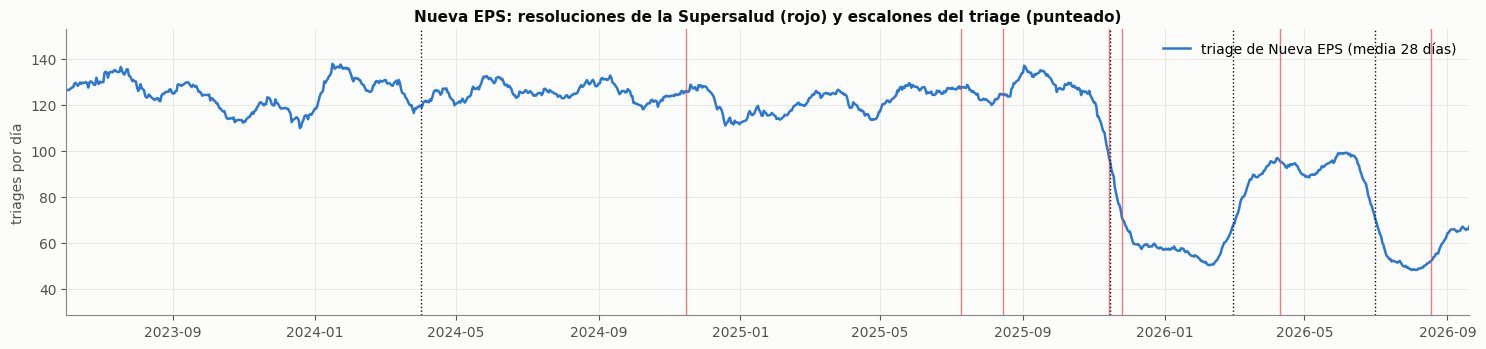

Resoluciones sobre Nueva EPS: ['2024-11-15', '2025-07-10', '2025-08-15', '2025-11-14', '2025-11-25', '2026-04-10', '2026-08-18']


In [5]:
f = glob.glob(str(RAIZ / "calendarios/capturas/medidas/*/CTFT21-Listado*EPS.csv"))[-1]
m = pd.read_csv(f); col = next(c for c in m.columns if c.upper().startswith("RESOLU"))
MES = {"enero": 1, "febrero": 2, "marzo": 3, "abril": 4, "mayo": 5, "junio": 6, "julio": 7, "agosto": 8, "septiembre": 9, "octubre": 10, "noviembre": 11, "diciembre": 12}
ev = []
for _, r in m.iterrows():
    for d, mes, a in re.findall(r"(\d{1,2}) de (\w+) del? (\d{4})", str(r[col]).lower()):
        if mes in MES: ev.append({"eps": r["ENTIDAD"].split("\n")[0].strip(), "fecha": pd.Timestamp(int(a), MES[mes], int(d))})
EV = pd.DataFrame(ev).drop_duplicates().sort_values(["eps", "fecha"])
print(EV.groupby("eps").fecha.agg(["min", "max", "count"]).rename(columns={"min": "primera resolución", "max": "última", "count": "resoluciones"}).to_string())
ne = EV[EV.eps.str.upper().str.contains("NUEVA")].fecha
fig, ax = plt.subplots(figsize=(15, 3.6))
ax.plot(D.index, D["Nueva EPS"].rolling(28, center=True, min_periods=14).mean(), color=AZUL, lw=1.8, label="triage de Nueva EPS (media 28 días)")
for d in ne: ax.axvline(d, color=ROJO, lw=1, alpha=.7)
for fsc in ESCALONES: ax.axvline(pd.Timestamp(fsc), color=TINTA, lw=1, ls=":")
ax.set_xlim(pd.Timestamp("2023-06-01"), D.index[-1]); ax.legend(loc="upper right"); ax.set_ylabel("triages por día")
ax.set_title("Nueva EPS: resoluciones de la Supersalud (rojo) y escalones del triage (punteado)"); plt.tight_layout(); plt.show()
print("Resoluciones sobre Nueva EPS:", [d.date().isoformat() for d in ne])

**Lectura.**

- **Siete EPS con presencia en la región están intervenidas o bajo medida especial:** Nueva EPS, Asmet, Coosalud, Emssanar, Famisanar, SOS y Capresoca. Cada una acumula de 6 a 12 resoluciones.
- **Sobre Nueva EPS hay 7 resoluciones con fecha.** Dos de ellas (**14 y 25 de noviembre de 2025**) coinciden con el escalón del **15 de noviembre de 2025**, la caída más grande del triage.
- Los otros dos escalones (marzo y julio de 2026) **no tienen una resolución en la misma fecha**: la del 10 de abril de 2026 llega después de la recuperación de marzo, y no hay ninguna cerca de julio.
- **Las resoluciones explican uno de tres escalones.** Los otros dos probablemente son **decisiones de contratación** entre el hospital y la EPS, que no son públicas. Es el pendiente #11 del propietario.
- **Límite:** la tabla solo lista las resoluciones de las medidas **vigentes**, y por eso la de Nueva EPS empieza en noviembre de 2024 y no en abril de 2024, cuando inició la intervención. Desde ahora la captura semanal guarda cada versión.

---
# 5. Las variables candidatas para el modelo

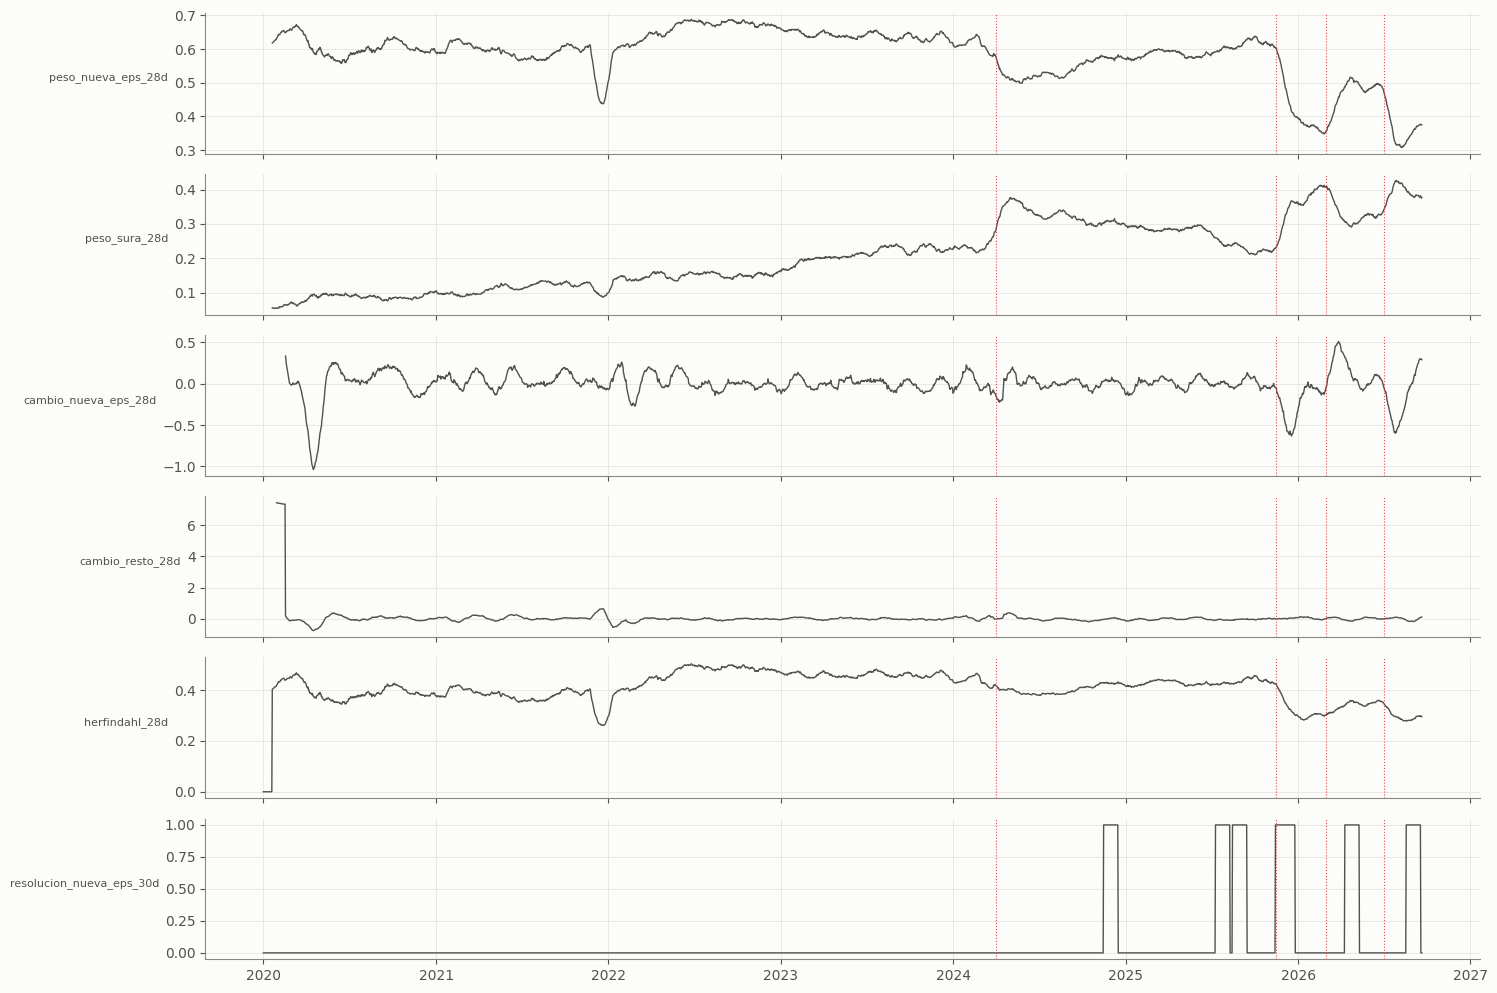

,desde,¿se conoce al predecir?,fuente
peso_nueva_eps_28d,2020-01-20,sí,triage del hospital
peso_sura_28d,2020-01-20,sí,triage del hospital
cambio_nueva_eps_28d,2020-02-17,sí,triage del hospital
cambio_resto_28d,2020-01-29,sí,triage del hospital
herfindahl_28d,2020-01-01,sí,triage del hospital
resolucion_nueva_eps_30d,2020-01-01,sí,Supersalud (fecha pública)


In [6]:
P28 = D.rolling(28, min_periods=20).sum(); tot28 = P28.sum(axis=1)
V = pd.DataFrame({"peso_nueva_eps_28d": P28["Nueva EPS"] / tot28, "peso_sura_28d": P28["SURA"] / tot28,
                  "cambio_nueva_eps_28d": np.log1p(P28["Nueva EPS"]) - np.log1p(P28["Nueva EPS"].shift(28)),
                  "cambio_resto_28d": np.log1p(P28.drop(columns="Nueva EPS").sum(axis=1)) - np.log1p(P28.drop(columns="Nueva EPS").sum(axis=1).shift(28)),
                  "herfindahl_28d": ((P28.div(tot28, axis=0)) ** 2).sum(axis=1)})
res = pd.Series(0.0, index=D.index)
for d in ne: res[d:d + pd.Timedelta(days=30)] = 1
V["resolucion_nueva_eps_30d"] = res
fig, axes = plt.subplots(len(V.columns), 1, figsize=(15, 10), sharex=True)
for ax, c in zip(axes, V.columns):
    ax.plot(V.index, V[c], color=TINTA2, lw=1); ax.set_ylabel(c, fontsize=8, rotation=0, ha="right")
    for fsc in ESCALONES: ax.axvline(pd.Timestamp(fsc), color=ROJO, lw=.8, ls=":")
plt.tight_layout(); plt.show()
disp = pd.DataFrame({"desde": [V[c].first_valid_index().date() for c in V], "¿se conoce al predecir?": ["sí"] * len(V.columns),
                     "fuente": ["triage del hospital"] * 5 + ["Supersalud (fecha pública)"]}, index=V.columns)
disp

**Lectura. Seis variables de red quedan listas para el modelo**, todas conocidas el día de la predicción:

- **el peso de Nueva EPS y de SURA en el triage (28 días):** el estado de la red;
- **el cambio de 28 días de Nueva EPS y del resto:** si la red se está moviendo;
- **el índice de Herfindahl:** cuánto depende el hospital de una sola aseguradora;
- **la bandera de resolución de la Supersalud sobre Nueva EPS en los últimos 30 días.**

La **afiliación mensual por EPS** (desde julio de 2025) y el **uso por afiliado** todavía no sirven para entrenar, porque son 14 meses. Se acumulan con la captura semanal y entrarán cuando haya historia.

**Límite de fondo:** las cinco primeras salen del propio triage. **Describen la red, pero no la anticipan:** cuando el peso de Nueva EPS cae, el escalón ya pasó. Lo que anticiparía es la información de **contratación y suspensiones**, que el hospital tiene y no es pública.

---
# 6. Lo que deja este cuaderno

**Lo que deja este cuaderno:**

1. **La red de salud del SES son dos aseguradoras, y las dos mueven el nivel:** SURA subiendo desde 2020 (escalón de abril de 2024) y Nueva EPS cayendo en 2025-2026.
2. **La caída de Nueva EPS es, sobre todo, de acceso:** −20 % de afiliados, −60 % de triage. El uso por afiliado se redujo a la mitad.
3. **Cuando Nueva EPS cae, nadie compensa en el SES** (11-16 %). Esos pacientes se van a otro lugar.
4. **Las resoluciones de la Supersalud explican uno de los tres escalones** (noviembre de 2025). Los otros dos dependen de decisiones de contratación que no son públicas.
5. **Ya hay panel externo de todas las EPS**, con afiliación mensual, medidas y BDUA capturadas cada semana. Faltan las quejas (PQRD) y los giros de ADRES.

**Para el modelo:** entran las 6 variables de red de la sección 5. **Lo que de verdad anticiparía los escalones es el calendario institucional de contratación entre el SES y cada EPS.** Solo el propietario puede conseguirlo, y es la pieza que más error explicaría.